# ZelaBairro — Modelo de prioridade das ocorrências

**CitizenTech:** ZelaBairro · **Integrante:** Joel — RM 560796 — 2ESPS

## 1. Problema

A subprefeitura recebe dezenas de ocorrências por dia (lixo, poste apagado, buraco, calçada, árvore) pelo app, por sensores e pelo balcão. **O operador precisa decidir rapidamente o que atender primeiro.** Hoje o terminal usa uma regra fixa de pontos; queremos um modelo que **aprenda com as triagens já feitas** e preveja a prioridade (**Baixa, Média ou Alta**) de uma ocorrência nova.

- **Tipo de tarefa:** classificação multiclasse (3 classes ordenadas).
- **Quem usa a previsão:** o operador, no terminal WinForms. A previsão aparece como sugestão, com a confiança; **a decisão final é humana**.
- **Métrica principal:** **F1-macro**. As classes são desbalanceadas (há menos casos "Alta") e errar uma ocorrência Alta é o erro mais caro, então a acurácia sozinha esconderia o problema. Acompanhamos também o **recall da classe Alta**.

## 2. Origem dos dados

**Os dados são simulados.** O regulamento da GS proíbe dados pessoais reais, e o ZelaBairro ainda não tem histórico. Geramos um histórico de **3.000 ocorrências já triadas**, com regras e premissas documentadas abaixo, para que o processo seja **reproduzível** (semente fixa) e auditável.

Premissas da simulação (baseadas na conversa com quem vive o problema e no funcionamento da API):
- Volume por categoria: lixo é o mais frequente, árvore o menos.
- Prazo (SLA) de cada categoria igual ao cadastrado na API: lixo 3, iluminação 5, buraco 10, calçada 15, árvore 7 dias.
- Sensores (ESP32) só existem para **lixo** (lixeira) e **iluminação** (poste com LDR).
- A prioridade dada pelo operador depende do **risco da categoria**, do **quanto do prazo já foi consumido**, das **confirmações de vizinhos**, da **foto** como evidência e de **combinações** (ex.: árvore confirmada por vizinhos é quase sempre Alta; lixeira medida por sensor e já fora do prazo também), **com ruído**, porque operadores diferentes discordam.

> A coluna `bairro_id` é gerada mas **não é usada como variável**: não queremos que o modelo aprenda a dar menos prioridade a um bairro do que a outro (ODS 10, redução das desigualdades).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, recall_score, classification_report, confusion_matrix

SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

# Paleta (prioridade é ordinal: um único tom, do claro ao escuro)
COR_PRIORIDADE = {"Baixa": "#86b6ef", "Media": "#2a78d6", "Alta": "#104281"}
COR_SERIE = "#2a78d6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True})

Path("data").mkdir(exist_ok=True)
Path("modelo").mkdir(exist_ok=True)

## 3. Geração do dataset simulado

In [2]:
N = 3000
CATEGORIAS = {  # id: (nome, prazo em dias, frequência, risco base)
    1: ("Lixo e descarte irregular", 3, 0.32, 1.0),
    2: ("Iluminação pública",        5, 0.22, 1.6),
    3: ("Buraco na via",            10, 0.22, 1.8),
    4: ("Calçada danificada",       15, 0.14, 1.2),
    5: ("Árvore e poda",             7, 0.10, 2.4),
}
ids = np.array(list(CATEGORIAS))
categoria_id = rng.choice(ids, size=N, p=[CATEGORIAS[i][2] for i in ids])
prazo_dias = np.array([CATEGORIAS[c][1] for c in categoria_id])
risco = np.array([CATEGORIAS[c][3] for c in categoria_id])

# Origem: sensores só para lixo (lixeira) e iluminação (poste)
origem = rng.choice(["App", "Terminal"], size=N, p=[0.82, 0.18]).astype(object)
tem_sensor = np.isin(categoria_id, [1, 2])
origem[tem_sensor & (rng.random(N) < 0.35)] = "Sensor"

# Dias em aberto no momento da triagem (cauda longa, proporcional ao prazo)
dias_em_aberto = np.floor(rng.gamma(shape=1.6, scale=prazo_dias * 0.55)).astype(int)
uso_prazo = dias_em_aberto / prazo_dias

# Confirmações de vizinhos (mais em problemas graves e antigos; sensores não recebem)
lam = 0.4 + 0.5 * risco + 0.6 * np.minimum(uso_prazo, 2)
confirmacoes = rng.poisson(lam)
confirmacoes[origem == "Sensor"] = rng.poisson(0.2, size=(origem == "Sensor").sum())

# Foto: comum no app, rara no balcão, inexistente no sensor
p_foto = np.select([origem == "App", origem == "Terminal"], [0.72, 0.05], default=0.0)
tem_foto = (rng.random(N) < p_foto).astype(int)

bairro_id = rng.integers(1, 6, size=N)  # gerado, mas NÃO usado como variável (ver seção 2)

# ---- Decisão do operador (rótulo), com interações e ruído ----
pontos = (
    1.6 * risco
    + 2.2 * np.minimum(uso_prazo, 2.0)
    + 0.75 * np.minimum(confirmacoes, 5)
    + 0.6 * tem_foto
    + 0.8 * (origem == "Sensor")
)
pontos += 2.5 * ((categoria_id == 5) & (confirmacoes >= 2))          # árvore confirmada: risco de queda
pontos += 2.0 * ((origem == "Sensor") & (uso_prazo > 1.0))          # sensor + prazo estourado
pontos += 1.5 * ((categoria_id == 2) & (dias_em_aberto >= 7))       # rua escura por mais de uma semana
pontos -= 1.2 * ((categoria_id == 4) & (confirmacoes == 0))         # calçada sem ninguém confirmar
pontos += rng.normal(0, 1.1, size=N)                                 # discordância entre operadores

corte_media, corte_alta = np.quantile(pontos, [0.42, 0.78])
prioridade = np.where(pontos >= corte_alta, "Alta", np.where(pontos >= corte_media, "Media", "Baixa"))

df = pd.DataFrame({
    "categoria_id": categoria_id,
    "categoria": [CATEGORIAS[c][0] for c in categoria_id],
    "bairro_id": bairro_id,
    "origem": origem,
    "prazo_dias": prazo_dias,
    "dias_em_aberto": dias_em_aberto,
    "confirmacoes": confirmacoes,
    "tem_foto": tem_foto,
    "prioridade": prioridade,
})
df.to_csv("data/ocorrencias_historico.csv", index=False, encoding="utf-8")
print(df.shape)
df.head()

(3000, 9)


,categoria_id,categoria,bairro_id,origem,prazo_dias,dias_em_aberto,confirmacoes,tem_foto,prioridade
0,4,Calçada danificada,5,Terminal,15,1,0,0,Baixa
1,2,Iluminação pública,4,Sensor,5,7,0,0,Alta
2,4,Calçada danificada,2,App,15,12,4,0,Media
3,3,Buraco na via,4,App,10,17,2,1,Media
4,1,Lixo e descarte irregular,4,Sensor,3,3,0,0,Media


## 4. Análise exploratória

In [3]:
print("Valores ausentes por coluna:\n", df.isna().sum().to_string(), sep="")
print("\nDistribuição da prioridade:")
print(df["prioridade"].value_counts(normalize=True).reindex(["Baixa", "Media", "Alta"]).round(3).to_string())
df.describe().round(2)

Valores ausentes por coluna:
categoria_id      0
categoria         0
bairro_id         0
origem            0
prazo_dias        0
dias_em_aberto    0
confirmacoes      0
tem_foto          0
prioridade        0

Distribuição da prioridade:
prioridade
Baixa    0.42
Media    0.36
Alta     0.22


,categoria_id,bairro_id,prazo_dias,dias_em_aberto,confirmacoes,tem_foto
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,2.48,3.01,7.03,5.65,1.37,0.49
std,1.34,1.40,4.14,6.76,1.35,0.50
min,1.00,1.00,3.00,0.00,0.00,0.00
25%,1.00,2.00,3.00,1.00,0.00,0.00
50%,2.00,3.00,5.00,3.00,1.00,0.00
75%,3.00,4.00,10.00,7.00,2.00,1.00
max,5.00,5.00,15.00,64.00,7.00,1.00


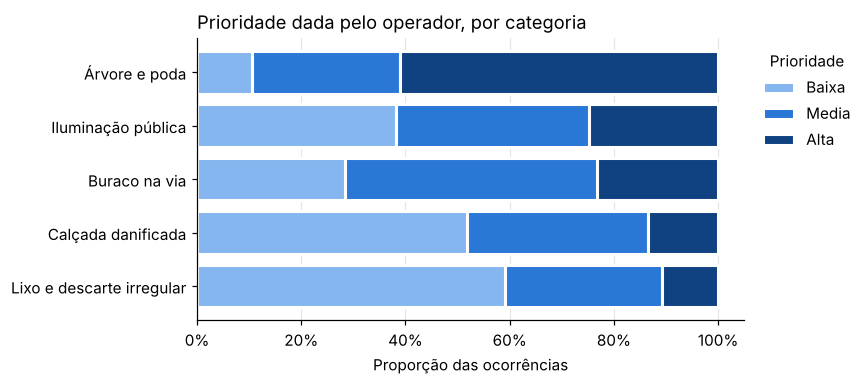

In [4]:
ordem = ["Baixa", "Media", "Alta"]
tab = pd.crosstab(df["categoria"], df["prioridade"], normalize="index").reindex(columns=ordem)
tab = tab.sort_values("Alta")

fig, ax = plt.subplots(figsize=(8, 3.6))
esquerda = np.zeros(len(tab))
for p in ordem:
    ax.barh(tab.index, tab[p], left=esquerda, color=COR_PRIORIDADE[p], label=p, edgecolor="white", linewidth=2)
    esquerda += tab[p].values
ax.set_xlabel("Proporção das ocorrências")
ax.set_title("Prioridade dada pelo operador, por categoria", loc="left")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.legend(title="Prioridade", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

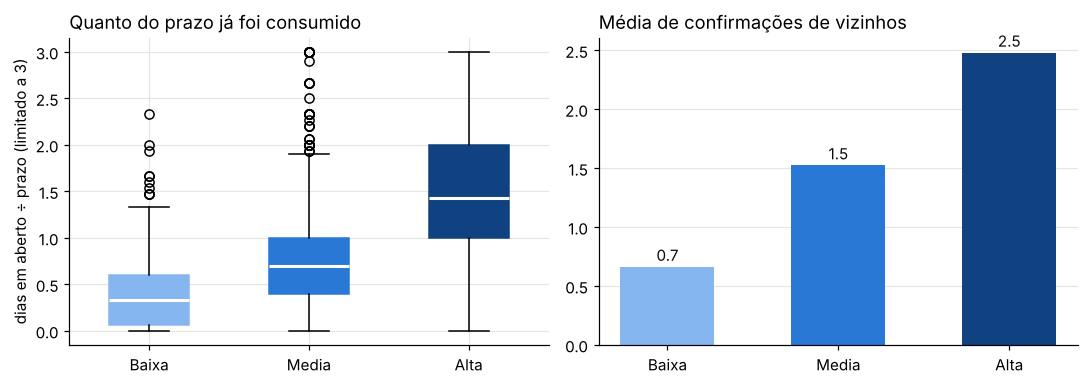

In [5]:
df["uso_prazo"] = df["dias_em_aberto"] / df["prazo_dias"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
dados = [df.loc[df["prioridade"] == p, "uso_prazo"].clip(upper=3) for p in ordem]
bp = axes[0].boxplot(dados, tick_labels=ordem, patch_artist=True, widths=0.5, medianprops={"color": "white", "linewidth": 2})
for caixa, p in zip(bp["boxes"], ordem):
    caixa.set_facecolor(COR_PRIORIDADE[p]); caixa.set_edgecolor(COR_PRIORIDADE[p])
axes[0].set_title("Quanto do prazo já foi consumido", loc="left")
axes[0].set_ylabel("dias em aberto ÷ prazo (limitado a 3)")

media_conf = df.groupby("prioridade")["confirmacoes"].mean().reindex(ordem)
axes[1].bar(ordem, media_conf, color=[COR_PRIORIDADE[p] for p in ordem], width=0.55)
for i, v in enumerate(media_conf):
    axes[1].text(i, v + 0.05, f"{v:.1f}", ha="center", color="#0b0b0b")
axes[1].set_title("Média de confirmações de vizinhos", loc="left")
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Leitura:** árvore e iluminação concentram mais casos Alta; a prioridade cresce com o **uso do prazo** e com as **confirmações**. As variáveis escolhidas carregam sinal, mas há sobreposição entre as classes (o ruído da triagem humana), então não esperamos um modelo perfeito.

## 5. Preparação

Variáveis usadas (todas disponíveis na API no momento da triagem, para que o terminal consiga calcular as mesmas entradas):

| Variável | Tratamento |
|---|---|
| categoria | one-hot (`cat_1` … `cat_5`) |
| prazo_dias, dias_em_aberto, confirmacoes | numéricas |
| uso_prazo | **criada**: dias_em_aberto ÷ prazo_dias (normaliza o atraso entre categorias com prazos diferentes) |
| tem_foto | 0/1 |
| origem | one-hot: `origem_sensor`, `origem_terminal` (App é a referência) |

Divisão **estratificada 80/20** (mesma proporção de classes em treino e teste) e **validação cruzada em 5 dobras** no treino para escolher hiperparâmetros. O teste só é usado no final.

In [6]:
FEATURES = ["cat_1", "cat_2", "cat_3", "cat_4", "cat_5",
            "prazo_dias", "dias_em_aberto", "uso_prazo", "confirmacoes",
            "tem_foto", "origem_sensor", "origem_terminal"]

def montar_features(d: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=d.index)
    for c in range(1, 6):
        X[f"cat_{c}"] = (d["categoria_id"] == c).astype(int)
    X["prazo_dias"] = d["prazo_dias"]
    X["dias_em_aberto"] = d["dias_em_aberto"]
    X["uso_prazo"] = d["dias_em_aberto"] / d["prazo_dias"]
    X["confirmacoes"] = d["confirmacoes"]
    X["tem_foto"] = d["tem_foto"]
    X["origem_sensor"] = (d["origem"] == "Sensor").astype(int)
    X["origem_terminal"] = (d["origem"] == "Terminal").astype(int)
    return X[FEATURES]

X = montar_features(df)
y = df["prioridade"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMENTE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
print("Treino:", X_treino.shape, " Teste:", X_teste.shape)

Treino: (2400, 12)  Teste: (600, 12)


## 6. Modelos

Comparamos, sempre com F1-macro em validação cruzada:
1. **Dummy** (sempre a classe mais comum): piso mínimo.
2. **Regra atual do terminal** (`Priorizador.cs`, reimplementada aqui): é o que o operador usa hoje, então **o modelo só vale a pena se superar a regra**.
3. **Regressão logística**: modelo linear.
4. **Árvore de decisão** com busca de hiperparâmetros.
5. **Random Forest**: referência de desempenho "teto".

In [7]:
def regra_atual(d: pd.DataFrame) -> np.ndarray:
    # Mesma lógica de desktop/ZelaBairro.Desktop/Services/Priorizador.cs
    risco_cat = {1: 2, 2: 3, 3: 3, 4: 2, 5: 4}
    pts = d["categoria_id"].map(risco_cat).to_numpy().astype(float)
    uso = (d["dias_em_aberto"] / d["prazo_dias"]).to_numpy()
    pts += np.where(uso >= 1, 3, np.where(uso >= 0.5, 1, 0))
    pts += np.minimum(d["confirmacoes"].to_numpy(), 3)
    pts += (d["origem"] == "Sensor").to_numpy().astype(int)
    return np.where(pts >= 7, "Alta", np.where(pts >= 4, "Media", "Baixa"))

f1_regra_treino = f1_score(y_treino, regra_atual(df.loc[X_treino.index]), average="macro")

modelos = {
    "Dummy (classe mais comum)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEMENTE, n_jobs=-1),
}
resultados = {"Regra atual do terminal": (f1_regra_treino, 0.0)}
for nome, modelo in modelos.items():
    s = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="f1_macro")
    resultados[nome] = (s.mean(), s.std())

busca = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=SEMENTE),
    {"max_depth": [3, 4, 5, 6, 7, 8], "min_samples_leaf": [5, 10, 20, 40]},
    cv=cv, scoring="f1_macro",
)
busca.fit(X_treino, y_treino)
resultados["Árvore de decisão (ajustada)"] = (busca.best_score_, busca.cv_results_["std_test_score"][busca.best_index_])
print("Melhores hiperparâmetros da árvore:", busca.best_params_)

tabela = pd.DataFrame(resultados, index=["F1-macro (média CV)", "desvio"]).T.sort_values("F1-macro (média CV)")
tabela.round(3)

Melhores hiperparâmetros da árvore: {'max_depth': 8, 'min_samples_leaf': 5}


,F1-macro (média CV),desvio
Dummy (classe mais comum),0.197,0.000
Regra atual do terminal,0.652,0.000
Árvore de decisão (ajustada),0.749,0.011
Random Forest,0.758,0.005
Regressão logística,0.762,0.012


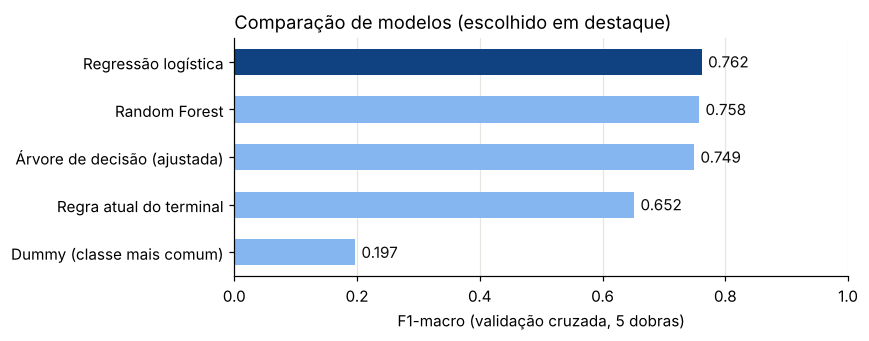

In [8]:
ESCOLHIDO = "Regressão logística"
fig, ax = plt.subplots(figsize=(8, 3.2))
cores = ["#104281" if n == ESCOLHIDO else "#86b6ef" for n in tabela.index]
ax.barh(tabela.index, tabela["F1-macro (média CV)"], color=cores, height=0.55)
for i, v in enumerate(tabela["F1-macro (média CV)"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", color="#0b0b0b")
ax.set_xlim(0, 1)
ax.set_xlabel("F1-macro (validação cruzada, 5 dobras)")
ax.set_title("Comparação de modelos (escolhido em destaque)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### Escolha: regressão logística

- **Melhor F1-macro na validação cruzada**, empatada tecnicamente com o Random Forest (diferença menor que o desvio entre dobras) e acima da árvore de decisão.
- **Probabilidades confiáveis:** a árvore, com folhas pequenas, chega a dizer "100% Alta"; a logística dá confianças graduais, mais honestas para mostrar ao operador.
- **Explicável:** cada variável tem um peso por classe, então o terminal mostra **quais fatores puxaram a previsão** (ex.: "+ uso do prazo, + confirmações").
- **Roda no terminal C# sem Python:** o modelo inteiro são 3×12 pesos, 3 interceptos e a média/desvio de cada variável, exportados num JSON pequeno. Um Random Forest exigiria centenas de árvores ou um servidor Python a mais na infraestrutura.
- `class_weight="balanced"` compensa o menor número de casos Alta.

## 7. Avaliação final no conjunto de teste (dados nunca vistos)

In [9]:
modelo = modelos[ESCOLHIDO].fit(X_treino, y_treino)
pred = modelo.predict(X_teste)
pred_regra = regra_atual(df.loc[X_teste.index])
pred_arvore = busca.best_estimator_.predict(X_teste)

def metricas(p):
    return [f1_score(y_teste, p, average="macro"), accuracy_score(y_teste, p),
            recall_score(y_teste, p, labels=["Alta"], average="macro")]

resumo = pd.DataFrame({"Regra atual": metricas(pred_regra), "Árvore": metricas(pred_arvore), "Logística (escolhido)": metricas(pred)},
                      index=["F1-macro", "Acurácia", "Recall da classe Alta"])
print(resumo.round(3).to_string())
print()
print(classification_report(y_teste, pred, labels=ordem, digits=3))

                       Regra atual  Árvore  Logística (escolhido)
F1-macro                     0.608   0.718                  0.761
Acurácia                     0.597   0.710                  0.757
Recall da classe Alta        0.795   0.803                  0.886

              precision    recall  f1-score   support

       Baixa      0.807     0.798     0.802       252
       Media      0.683     0.630     0.655       216
        Alta      0.770     0.886     0.824       132

    accuracy                          0.757       600
   macro avg      0.753     0.771     0.761       600
weighted avg      0.754     0.757     0.754       600



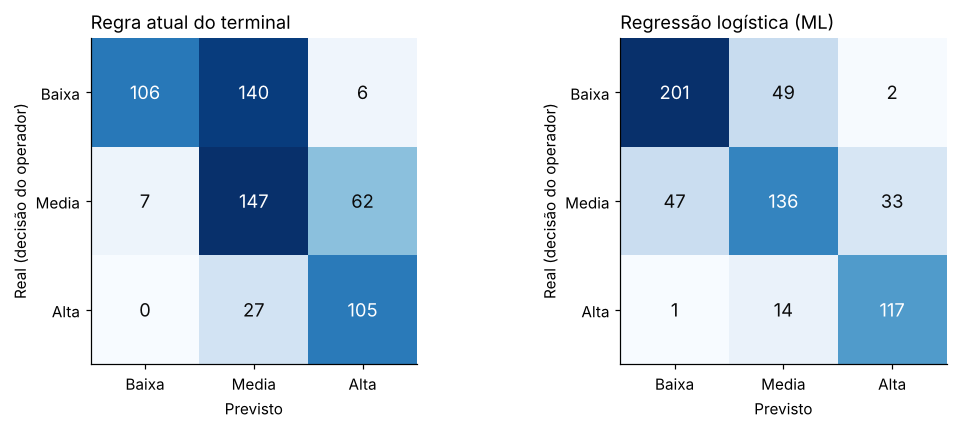

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, p) in zip(axes, [("Regra atual do terminal", pred_regra), ("Regressão logística (ML)", pred)]):
    m = confusion_matrix(y_teste, p, labels=ordem)
    ax.imshow(m, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() * 0.5 else "#0b0b0b", fontsize=12)
    ax.set_xticks(range(3), ordem); ax.set_yticks(range(3), ordem)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real (decisão do operador)")
    ax.set_title(titulo, loc="left"); ax.grid(False)
plt.tight_layout(); plt.show()

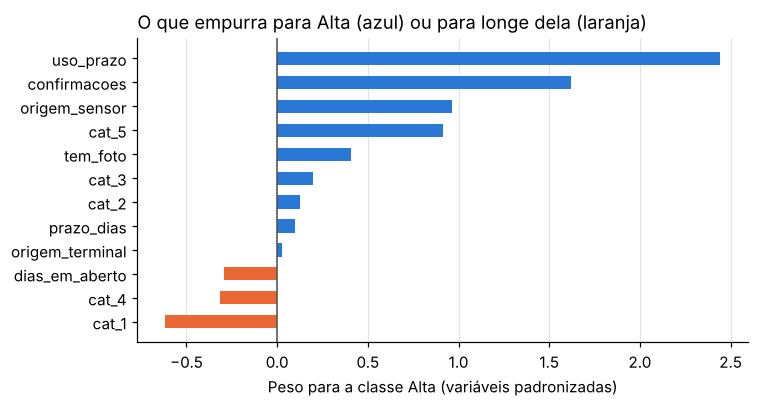

In [11]:
reg = modelo.named_steps["logisticregression"]
idx_alta = list(reg.classes_).index("Alta")
pesos = pd.Series(reg.coef_[idx_alta], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(pesos.index, pesos.values, color=["#eb6834" if v < 0 else "#2a78d6" for v in pesos.values], height=0.55)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_title("O que empurra para Alta (azul) ou para longe dela (laranja)", loc="left")
ax.set_xlabel("Peso para a classe Alta (variáveis padronizadas)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Leitura:** o **uso do prazo** e as **confirmações de vizinhos** são o que mais empurra para Alta, seguidos de **sensor** e de **árvore**; **lixo** e **calçada** puxam para baixo. É coerente com a forma como o operador decide, o que dá confiança de que o modelo não aprendeu algo absurdo. (`dias_em_aberto` aparece levemente negativo porque o efeito do atraso já está em `uso_prazo`, que considera o prazo de cada categoria.)

## 8. Exportação e integração na solução

O modelo é salvo em `modelo/modelo_prioridade.json`: a ordem das variáveis, a **média e o desvio** de cada uma (padronização) e os **pesos e interceptos** de cada classe. O **terminal WinForms** (`desktop/.../Services/ModeloPrioridade.cs`) lê esse arquivo, calcula as mesmas 12 variáveis a partir da ocorrência vinda da API e aplica

`z = (x − média) / desvio` → `logit_k = intercepto_k + Σ peso_kj · z_j` → `probabilidade = softmax(logits)`

O operador vê **"Previsão do modelo: Alta (84%)"** com os principais fatores, ao lado da regra antiga, e aplica com um clique.

Abaixo, conferimos que **essa conta feita "na mão" a partir do JSON dá as mesmas probabilidades** que o scikit-learn, ou seja, o modelo no C# é exatamente o modelo avaliado aqui.

In [12]:
escala = modelo.named_steps["standardscaler"]
exportado = {
    "modelo": "LogisticRegression (multinomial) + StandardScaler",
    "versao": "1.0.0",
    "treinado_em": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "features": FEATURES,
    "classes": [str(c) for c in reg.classes_],
    "media": [round(float(v), 10) for v in escala.mean_],
    "desvio": [round(float(v), 10) for v in escala.scale_],
    "pesos": [[round(float(v), 10) for v in linha] for linha in reg.coef_],
    "interceptos": [round(float(v), 10) for v in reg.intercept_],
    "metricas_teste": {k: round(float(v), 4) for k, v in resumo["Logística (escolhido)"].items()},
}
Path("modelo/modelo_prioridade.json").write_text(json.dumps(exportado, ensure_ascii=False, indent=1), encoding="utf-8")

def prever_pelo_json(m, x):
    z = (np.asarray(x, dtype=float) - np.array(m["media"])) / np.array(m["desvio"])
    logits = np.array(m["interceptos"]) + np.array(m["pesos"]) @ z
    e = np.exp(logits - logits.max())
    return e / e.sum()

carregado = json.loads(Path("modelo/modelo_prioridade.json").read_text(encoding="utf-8"))
probs_json = np.array([prever_pelo_json(carregado, linha.values) for _, linha in X_teste.iterrows()])
probs_sk = modelo.predict_proba(X_teste)
classes_json = np.array(carregado["classes"])[probs_json.argmax(axis=1)]
print(f"Maior diferença de probabilidade JSON x scikit-learn: {np.abs(probs_json - probs_sk).max():.2e}")
print(f"Concordância das previsões no teste: {np.mean(classes_json == pred):.1%}")
assert np.mean(classes_json == pred) == 1.0

Maior diferença de probabilidade JSON x scikit-learn: 1.23e-10
Concordância das previsões no teste: 100.0%


### Exemplo: uma ocorrência nova, como o terminal recebe da API

In [13]:
nova = pd.DataFrame([{"categoria_id": 5, "origem": "App", "prazo_dias": 7, "dias_em_aberto": 4, "confirmacoes": 3, "tem_foto": 1}])
probs = modelo.predict_proba(montar_features(nova))[0]
print("Árvore com galho quebrado, 4 dias em aberto, 3 vizinhos confirmaram, com foto:")
for c, p in sorted(zip(reg.classes_, probs), key=lambda t: -t[1]):
    print(f"  {c:<6} {p:.0%}")

Árvore com galho quebrado, 4 dias em aberto, 3 vizinhos confirmaram, com foto:
  Alta   93%
  Media  7%
  Baixa  0%


## 9. Conclusões e limites

- O modelo **supera a regra fixa** que o terminal usava em F1-macro e acurácia, mantendo um bom **recall da classe Alta**, que é o erro mais caro.
- **Limite principal:** os dados são **simulados**. Os números mostram que o *processo* funciona; quando o ZelaBairro estiver em uso, o mesmo notebook deve ser re-treinado com as triagens reais exportadas da API (`GET /api/ocorrencias`), e as premissas da seção 2 devem ser revistas.
- **Interações:** a simulação tem combinações (ex.: árvore + confirmações) que um modelo linear capta só em parte. Com dados reais, vale comparar de novo com Random Forest.
- **Viés:** o bairro foi deixado de fora de propósito. Ao re-treinar com dados reais, é preciso conferir se o desempenho é parecido em todos os bairros.
- **Humano no controle:** a previsão é uma **sugestão**. O operador decide, e o histórico do terminal registra quando ele aplica a previsão do modelo, o que vira dado para a próxima versão.